In [1]:
# basic
from copy import deepcopy
from pathlib import Path
from typing import Optional, Literal
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import astropy.units as u
from astropy.io import fits
from astropy.table import Table
from scipy.ndimage import median_filter

# zs_scopesim_tools convenience routines
import zs_scopesim_tools.helpers
from zs_scopesim_tools.helpers import (disable_scopesim_top_level_catch, warning_prevent_sync_alt_ra_dec,
                                       ignore_warnings, set_scopesim_log_level, make_local_output_dir, configure_irdb_path, timed, list_effects, simulate, save_zshooter_readout, electron_readouts, combine_readouts)
# scopesim and scopesim source creation related
import scopesim as sim
import scopesim_templates as sim_tp
from scopesim.source.source import Source
from scopesim.source import source_templates
from zs_scopesim_tools.sources import lamp_flat, transient, kilonova_spectra
from zs_scopesim_tools.plots import PlotScene, plot_readout_overview
from synphot.units import convert_flux

# DRP
from zsdrp.ZSHOOTER import ZSHOOTER
import zsdrp.pipe, zsdrp.steps


configure_irdb_path()  # REQUIRED the first time after installation, sets local IRDB directory path in ScopeSim
set_scopesim_log_level("warning")  # set ScopeSim log toggles
disable_scopesim_top_level_catch()
ignore_warnings()
logging.disable(logging.INFO)

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/combine_frames.py:15: DeprecationWarning: Please import `median_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import median_filter

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/util.py:17: DeprecationWarning: Please import `median_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import median_filter

py.warnings - WARNING: /Users/jibailey/src/PyReduce-xshooter/pyreduce/trace.py:29: DeprecationWarning: Please import `gaussian_filter1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import gaussian_filter1d, median_filter, uniform_filter1d

py.warnings - WARNING: /Use

# Alternative detector reduction

This check loads the editable `SPEC_ALTDETECT` package from IRDB. In this run it uses untapered CCDs in B/G/R and 18 um H2RGs in YJ/H/K. It simulates calibration frames, a flat-AB standard and an independent flat-AB source/blank pair with the explicit exposure settings below. Reduction uses the actual configured trace geometry and saved detector WCS. The short-slit TRACE frames are used in every channel, with mode-specific DRP settings.

The primary [kilonova notebook](../../notebooks/01_Kilonovae.ipynb) exposes the same detector-mode setting. This check isolates calibration, geometry and flux recovery from the faint-source profile-fit failure documented in [the operating-point assessment](../../docs/detector-operating-points.md#reduction-and-verification).

In [2]:
DETECTOR_MODE = "SPEC_ALTDETECT"
workspace = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path/"env/zshooter-stack.toml").exists())
OUTDIR = workspace/"notebooks/01_Kilonovae_detectors"/f"{DETECTOR_MODE}_yj_h2rg"
OUTDIR.mkdir(parents=True, exist_ok=True)
# Explicit DIT and independent integrations in B/G/R/YJ/H/K order.
SCIENCE_EXPOSURES = {
    "SPEC": [(1200, 3)]*3 + [(100, 36), (30, 120), (60, 60)],
    "SPEC_ALTDETECT": [(1200, 3)]*3 + [(300, 12), (90, 40), (150, 24)],
}
CALIBRATION_DITS = {
    "SPEC": {"arcs": [40, 40, 3, .5, 4, 2], "flat": [120, 10, 3, .4, .4, .4], "standard": [100]*6},
    "SPEC_ALTDETECT": {"arcs": [40, 40, 3, 2, 10, 5], "flat": [120, 10, 3, 1.2, 1.2, 1.2], "standard": [100]*6},
}
exposure_rows = []

In [3]:
zs_config = sim.UserCommands(use_instrument="ZShooter_v2", set_modes=[DETECTOR_MODE])

In [4]:
@timed
def update_params_and_observe(object_name: str,
                              imagetype: str,
                              source: Source,
                              exptimes: Optional[list | float] = None,
                              ndit: int | list = 1,
                              output_dir: Optional[str | Path]=None,
                              *,
                              disable_effects: Optional[list[str]]=None,
                              disable_backgrounds: Optional[list[Literal["sky", "sky_continuum", "sky_lines"]]]=None,
                              airmass: Optional[float]=None,
                              seeing: Optional[float]=None,
                              brightness: Optional[Literal["bright", "grey", "dark"]]=None,
                              vis_slit: Optional[float]=None,
                              nir_slit: Optional[float]=None,
                              pixel_scale: Optional[float]=None,
                              pupil_angle: Optional[float]=None,
                              ao_on: bool=False,
                              diffuse_emissivity_on: bool=False,
                              params: Optional[dict]=None
                              ) -> tuple[list, sim.optics.OpticalTrain]:
    """
    :param object_name: Name of the Source object
    :param imagetype: IMAGETYPE keyword (BIAS, DOMEFLAT, TRACE, ARCS, SKY, SCIENCE)
    :param source: Source instance
    :param exptimes: List of exposure times in channel order (blue, green, red, yj, h, k) in seconds, or single value.
                If None, it is set to 0.0.
    :param ndit: independent integrations, one count per arm or a common count
    :param output_dir: Directory to save observed data in, FITS files are saved with {object_name}_{CHANNEL}.fits names
                        where CHANNEL is in [BLUE, GREEN, RED, YJ, H, K] (upper case)
    :param disable_effects: List of effect names to disable
    :param disable_backgrounds: List of background names to disable, options are "sky", "sky_continuum", or "sky_lines".
    :param airmass: Airmass
    :param seeing: Seeing (natural)
    :param brightness: Brightness of sky ("bright", "grey", or "dark")
    :param vis_slit: Slit width for Visible channel
    :param nir_slit: Slit width for NIR channel
    :param pixel_scale: Instrument pixel scale
    :param pupil_angle: Instrument pupil angle
    :param ao_on: True for AO correction on, defaults to False
    :param diffuse_emissivity_on: True for diffuse emissivity effect on, defaults to False
    :param params: Dict of any other UserCommands alias keys and values to set

    :return: tuple(HDUList, OpticalTrain)
    """
    if imagetype not in ["BIAS", "DOMEFLAT", "TRACE", "ARCS", "SKY", "SCIENCE", "RAW_OBJECT", "STANDARD_RAW"]:
        raise ValueError(f"Imagetype {imagetype} is incorrect! Choose from BIAS, DOMEFLAT, TRACE, ARCS, SKY, SCIENCE.")
    # load ZShooter_v2 irdb model config
    config = sim.UserCommands(use_instrument="ZShooter_v2", set_modes=[DETECTOR_MODE])
    # update with passed params
    config["!OBS.airmass"] = airmass if airmass else config["!OBS.airmass"]
    config["!OBS.seeing"] = seeing if seeing else config["!OBS.seeing"]
    config["!OBS.brightness"] = brightness if brightness else config["!OBS.brightness"]
    config["!OBS.pupil_angle"] = pupil_angle if pupil_angle else config["!OBS.pupil_angle"]
    config["!INST.vis_curr_slit"] = vis_slit if vis_slit else config["!INST.vis_curr_slit"]
    config["!INST.nir_curr_slit"] = nir_slit if nir_slit else config["!INST.nir_curr_slit"]
    config["!INST.pixel_scale"] = pixel_scale if pixel_scale else config["!INST.pixel_scale"]
    config["!INST.include_diffuse_emissivity"] = diffuse_emissivity_on
    config["!ATMO.ao_enabled"] = ao_on

    dits = [0.]*6 if exptimes is None else [exptimes]*6 if not isinstance(exptimes, list) else exptimes
    ndits = ndit if isinstance(ndit, list) else [ndit]*6
    config["!OBS.dit"], config["!OBS.ndit"] = dits[0], ndits[0]
    for dit, count, arm in zip(dits, ndits, ("blue", "green", "red", "yj", "h", "k"), strict=True):
        config[f"!OBS.dit_{arm}"] = dit
        config[f"!OBS.ndit_{arm}"] = count

    if params is not None and isinstance(params, dict):
        params = {key:val for key, val in params.items() if key in config}
        # USE THIS TO UPDATE THE CONFIG WITH NEW PROPERTIES, IT IS NOT A NORMAL DICT
        config.update_alias(config, params)
    # make sure airmass, ra, dec are in sync if all are provided
    warning_prevent_sync_alt_ra_dec(config)

    if output_dir is not None:
        output_dir = Path(output_dir)

    # call simulate(), it inits optical train, runs observe() and readout()
    print(f'Simulating {object_name}')
    zs, raw = simulate(config, source=source, disable_effects=disable_effects, disable_backgrounds=disable_backgrounds, hide_progress_bars=True)
    hdul = electron_readouts(zs, raw)
    for arm, readout in zip(("BLUE", "GREEN", "RED", "YJ", "H", "K"), hdul, strict=True):
        h = readout[1].header
        exposure_rows.append((object_name, DETECTOR_MODE, arm, h["DIT"], h["NDIT"], h["EXPTIME"], h["PEAKDIT"], h["WELLDEP"], h["EXNOISE"], h["RON"], h["DARK"]))
    print(f"Peak electrons per integration: {[round(readout[1].header['PEAKDIT']) for readout in hdul]}")
    # ScopeSim draws the accumulated photons and NDIT independent effective read noises.
    if output_dir is not None:
        save_zshooter_readout(raw, output_dir/"native", object_name=object_name, imagetype=imagetype, cmds=config, train=zs)
        save_zshooter_readout(hdul, output_dir, object_name=object_name, imagetype=imagetype, cmds=config, train=zs)
    return [hdul], zs

In [5]:
airmass = 1.3
seeing = 0.7
brightness = "dark"
vis_slit = 0.7
nir_slit = 0.7
ao_on = False
diffuse_emissivity_on = False
params = {"!OBS.mjdobs": 60310.25, "!SIM.spectral.spectral_bin_width": 1e-5} # in um, (== 0.1 Angstrom, use 0.05 Angstrom for smaller slit widths)

args = {'airmass':airmass, 'seeing':seeing, 'brightness':brightness, 'vis_slit':vis_slit, 'nir_slit':nir_slit,
        'ao_on': ao_on, 'diffuse_emissivity_on': diffuse_emissivity_on, 'params': params}

# creating a sub-directory in OUTDIR for this run config, naming it based on config params for uniqueness
output_dir = OUTDIR / f"kilonova_X-{airmass}_NS-{seeing}_{brightness}_slit-{vis_slit}_ao-{int(ao_on)}_optimal_variance"
output_dir.mkdir(parents=True, exist_ok=True)

overwrite_cals = True  # set True to redo cals
plot = True  # Set True for plotting

Simulating bias
Peak electrons per integration: [0, 0, 0, 0, 0, 0]
update_params_and_observe(bias): 67.6 s
Simulating arcs
Peak electrons per integration: [11429, 37300, 17763, 33481, 28685, 30299]
update_params_and_observe(arcs): 60.8 s
Simulating domeflat
Peak electrons per integration: [25211, 39028, 31498, 47099, 54798, 52715]
update_params_and_observe(domeflat): 65.5 s
Simulating trace
Peak electrons per integration: [25211, 39028, 31498, 47099, 54798, 52715]
update_params_and_observe(trace): 63.1 s


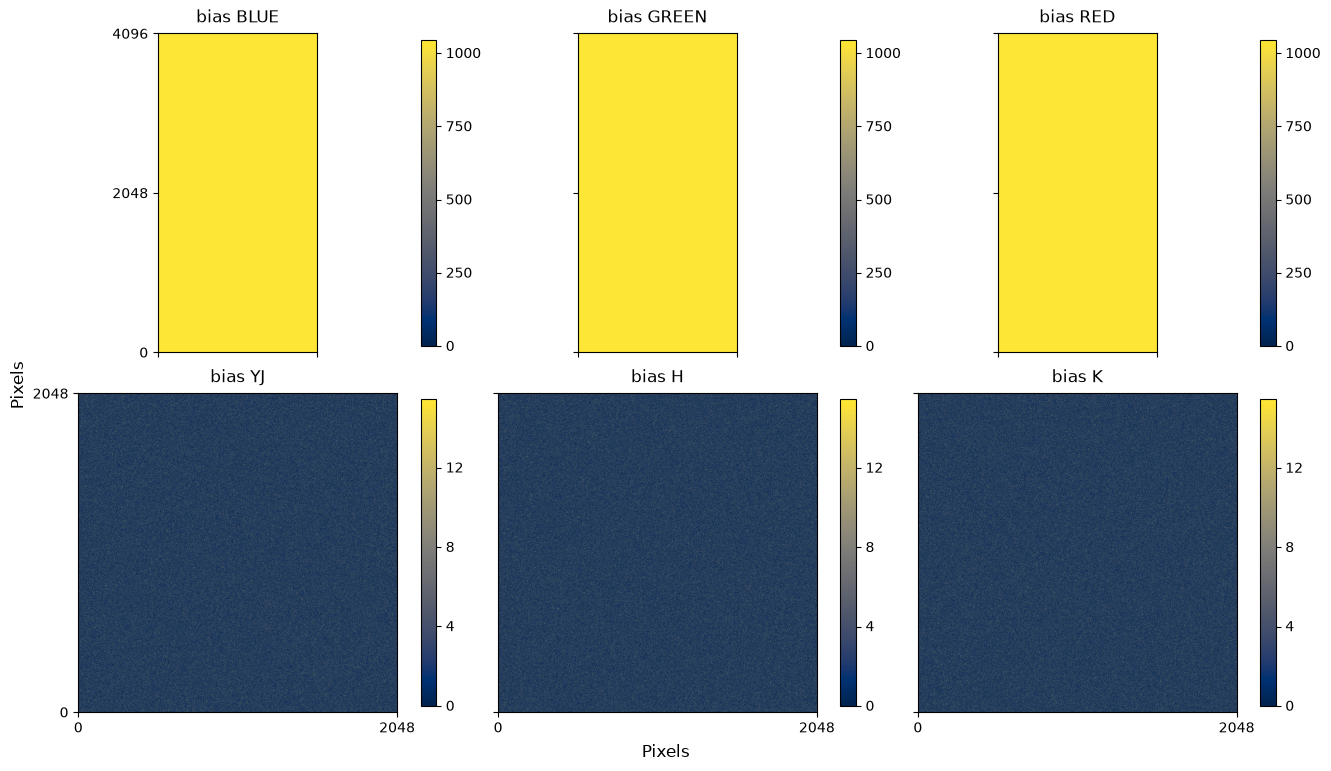

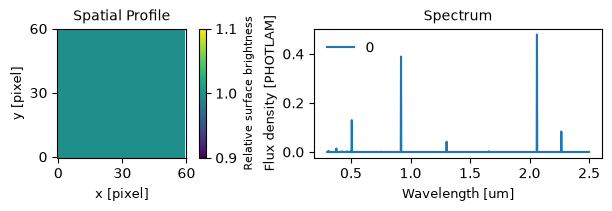

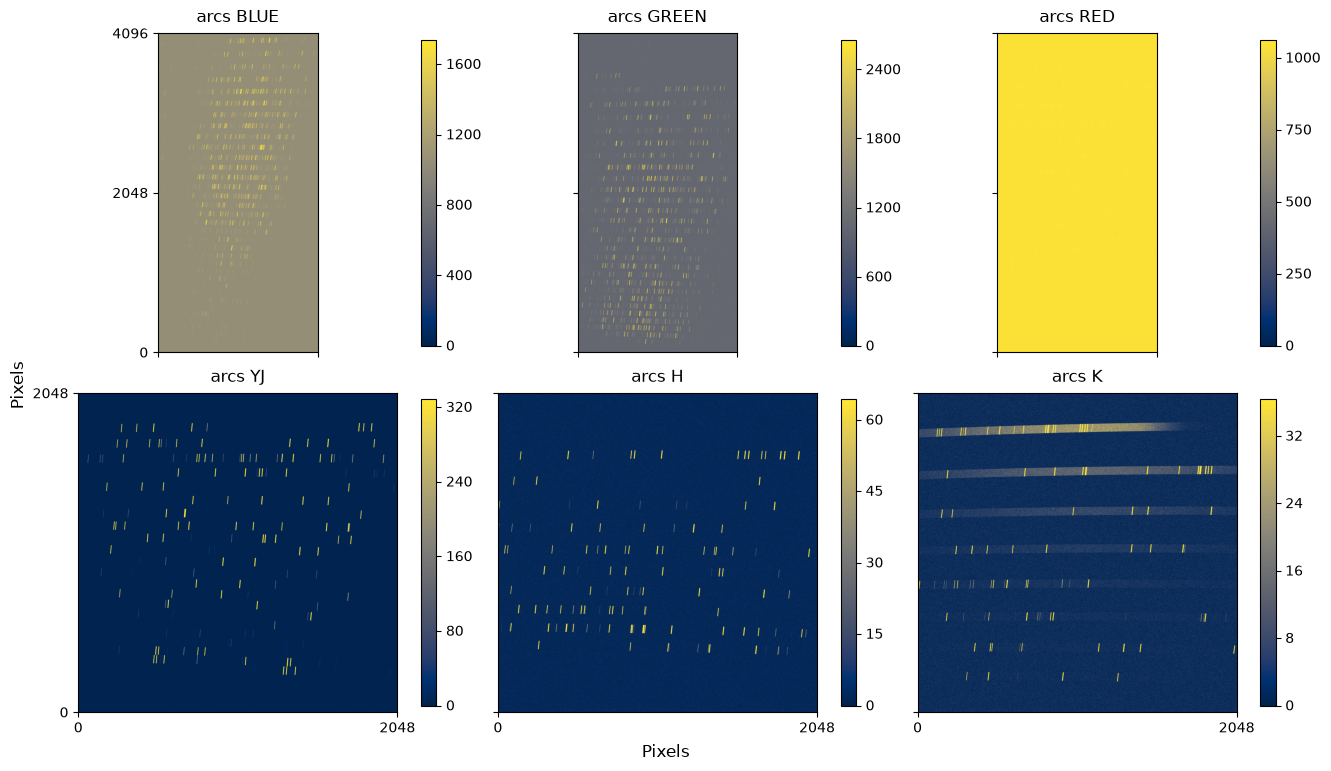

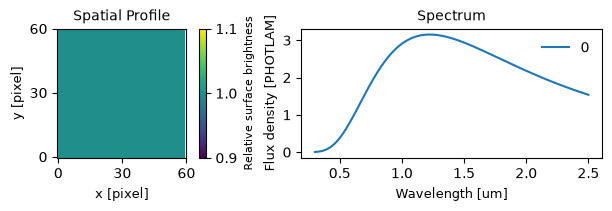

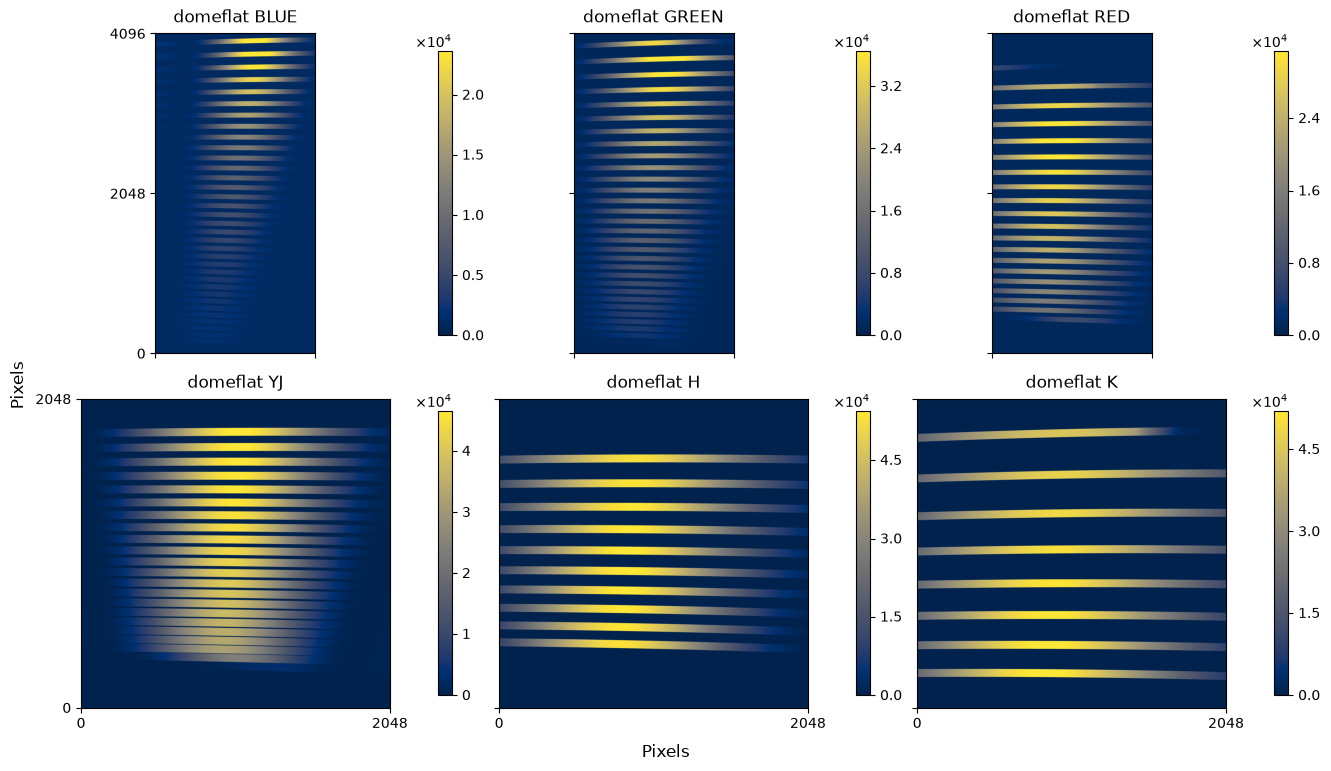

In [6]:
# for cals
disable_effects_cals = ["atmo_transmission", "continuum_emission", "airglow_and_interline_continuum",
                        "seeing_psf", "adc_residuals"]

rebuild_cals = overwrite_cals or any(len(list(output_dir.glob(f"{name}_0_*.fits"))) != 6 for name in ("bias", "arcs", "domeflat", "trace", "standard"))
if rebuild_cals:
    # bias
    bias_hduls, _ = update_params_and_observe(object_name="bias", imagetype="BIAS", source=None, exptimes=0,
                                             output_dir=output_dir, disable_effects=disable_effects_cals, **args)
    # arcs
    LAMP = lamp_flat()
    arcs_hduls, _ = update_params_and_observe(object_name="arcs", imagetype="ARCS", source=LAMP,
                                             exptimes=CALIBRATION_DITS[DETECTOR_MODE]["arcs"], output_dir=output_dir,
                                             disable_effects=disable_effects_cals, **args)
    # Calibration exposure settings are explicit above; readout warns if a detector limit is exceeded.
    # domeflat
    DOMEFLAT = sim_tp.calibration.flat_field(temperature=3000*u.K, amplitude=8*u.ABmag, filter_curve='V', extend=60)
    domeflat_hduls, _ = update_params_and_observe(object_name="domeflat", imagetype="DOMEFLAT", source=DOMEFLAT,
                                                 exptimes=CALIBRATION_DITS[DETECTOR_MODE]["flat"], output_dir=output_dir,
                                                 disable_effects=disable_effects_cals, **args)
    # A short illuminated slit separates the overlapping blue YJ orders for measured tracing.
    TRACE = sim_tp.calibration.flat_field(temperature=3000*u.K, amplitude=8*u.ABmag, filter_curve='V', extend=2)
    trace_hduls, _ = update_params_and_observe(object_name="trace", imagetype="TRACE", source=TRACE,
                                              exptimes=CALIBRATION_DITS[DETECTOR_MODE]["flat"], output_dir=output_dir,
                                              disable_effects=disable_effects_cals, **args)
    if plot:
        _, _ = plot_readout_overview(bias_hduls[0],
                                        titles=[f"bias {chan}" for chan in ["BLUE", "GREEN", "RED", "YJ", "H", "K"]])
        _, _ = PlotScene().from_source(LAMP)
        _, _ = plot_readout_overview(arcs_hduls[0],
                                        titles=[f"arcs {chan}" for chan in ["BLUE", "GREEN", "RED", "YJ", "H", "K"]])
        _, _ = PlotScene().from_source(DOMEFLAT)
        _, _ = plot_readout_overview(domeflat_hduls[0],
                                        titles=[f"domeflat {chan}" for chan in ["BLUE", "GREEN", "RED", "YJ", "H", "K"]])
    del bias_hduls, domeflat_hduls, trace_hduls, arcs_hduls

Simulating standard_raw
Peak electrons per integration: [58, 109, 127, 269, 299, 5221]
update_params_and_observe(standard_raw): 87.7 s
Simulating standard_background
Peak electrons per integration: [0, 0, 0, 1, 8, 5214]
update_params_and_observe(standard_background): 74.9 s


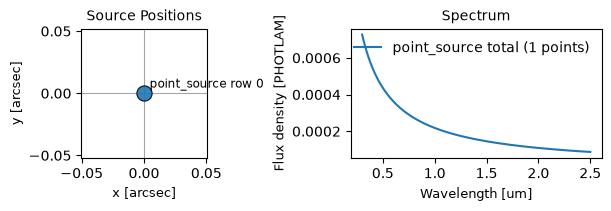

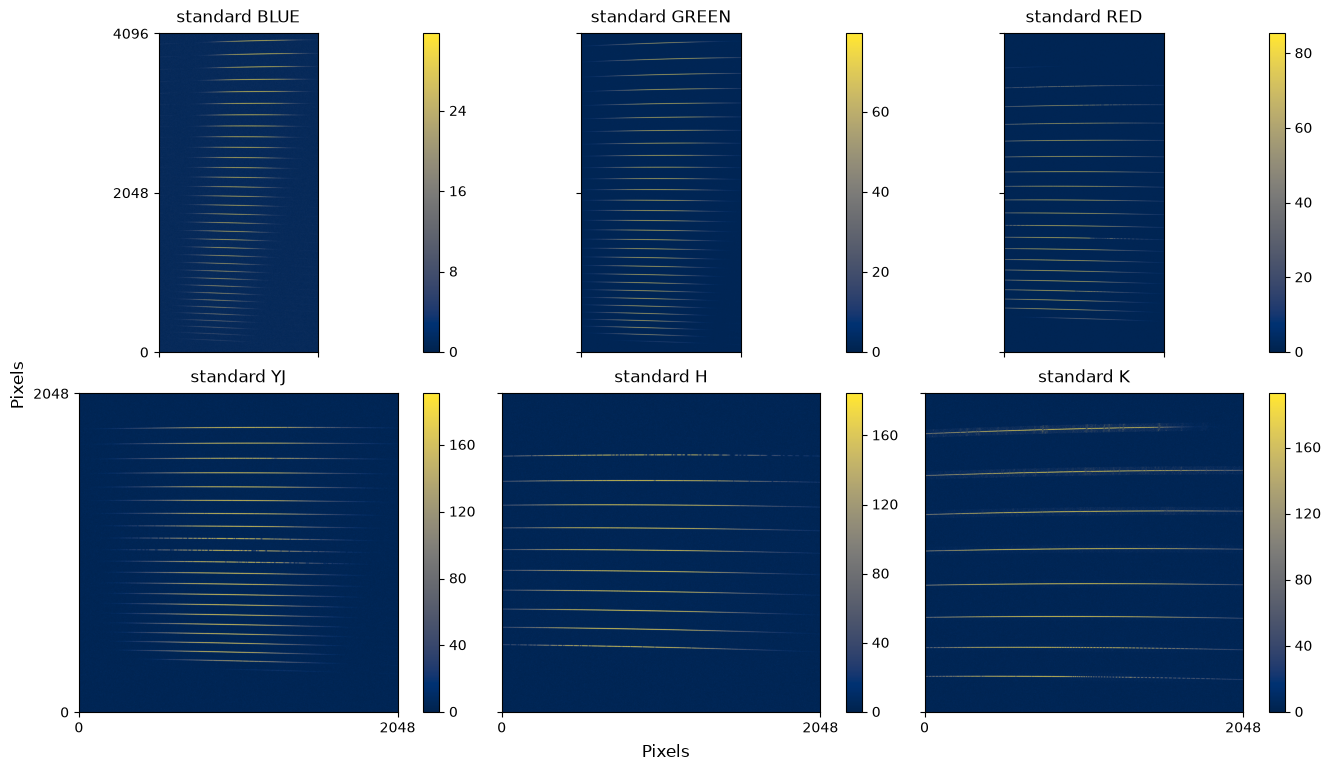

In [7]:
# Removing sky emission leaves telescope/instrument thermal emission in the standard.
# Subtract an independent blank exposure with the same settings, including its detector pedestal.
if rebuild_cals:
    STANDARD = sim_tp.misc.point_source(sed=source_templates.ab_spectrum(mag=16))
    std_hduls, std_train = update_params_and_observe(object_name="standard_raw", imagetype="SCIENCE", source=STANDARD,
                                                     exptimes=CALIBRATION_DITS[DETECTOR_MODE]["standard"], disable_backgrounds=["sky"], **args)
    save_zshooter_readout(std_hduls[0], output_dir, object_name="standard_raw", imagetype="STANDARD_RAW",
                         cmds=std_train.cmds, train=std_train)
    blank_hduls, _ = update_params_and_observe(object_name="standard_background", imagetype="SKY", source=None,
                                               exptimes=CALIBRATION_DITS[DETECTOR_MODE]["standard"], disable_backgrounds=["sky"], output_dir=output_dir, **args)
    std_hduls = [combine_readouts([std_hduls[0], blank_hduls[0]], [1, -1], source_indices=[0])]
    save_zshooter_readout(std_hduls[0], output_dir, object_name="standard", imagetype="SCIENCE",
                         cmds=std_train.cmds, train=std_train, extra_headers={"SUBTRACTED": True})
    if plot:
        _, _ = PlotScene().from_source(STANDARD)
        _, _ = plot_readout_overview(std_hduls[0], titles=[f"standard {chan}" for chan in ["BLUE", "GREEN", "RED", "YJ", "H", "K"]])
    del std_hduls, blank_hduls, std_train

Simulating FLAT_AB
Peak electrons per integration: [25, 5492, 5846, 30276, 48081, 43757]
update_params_and_observe(FLAT_AB): 105.7 s
Simulating FLAT_AB_sky
Peak electrons per integration: [10, 5463, 5819, 30266, 48076, 43755]
update_params_and_observe(FLAT_AB_sky): 91.1 s


,object,detector_mode,arm,DIT,NDIT,on_source_s,peak_e_per_integration,usable_well_e,F,read_noise_total_e,dark_e_s,well_fraction
0,bias,SPEC_ALTDETECT,BLUE,0.0,1,0.0,0.000000,60000,1.0,2.500000,0.000556,0.000000e+00
1,bias,SPEC_ALTDETECT,GREEN,0.0,1,0.0,0.000000,60000,1.0,2.500000,0.000556,0.000000e+00
2,bias,SPEC_ALTDETECT,RED,0.0,1,0.0,0.000000,60000,1.0,2.500000,0.000556,0.000000e+00
3,bias,SPEC_ALTDETECT,YJ,0.0,1,0.0,0.000000,60000,1.0,6.000000,0.006389,0.000000e+00
4,bias,SPEC_ALTDETECT,H,0.0,1,0.0,0.000000,60000,1.0,6.000000,0.006389,0.000000e+00
5,bias,SPEC_ALTDETECT,K,0.0,1,0.0,0.000000,60000,1.0,6.000000,0.006389,0.000000e+00
6,arcs,SPEC_ALTDETECT,BLUE,40.0,1,40.0,11428.898090,60000,1.0,2.500000,0.000556,1.904816e-01
7,arcs,SPEC_ALTDETECT,GREEN,40.0,1,40.0,37299.721467,60000,1.0,2.500000,0.000556,6.216620e-01
8,arcs,SPEC_ALTDETECT,RED,3.0,1,3.0,17762.652680,60000,1.0,2.500000,0.000556,2.960442e-01
9,arcs,SPEC_ALTDETECT,YJ,2.0,1,2.0,33480.918093,60000,1.0,6.000000,0.006389,5.580153e-01


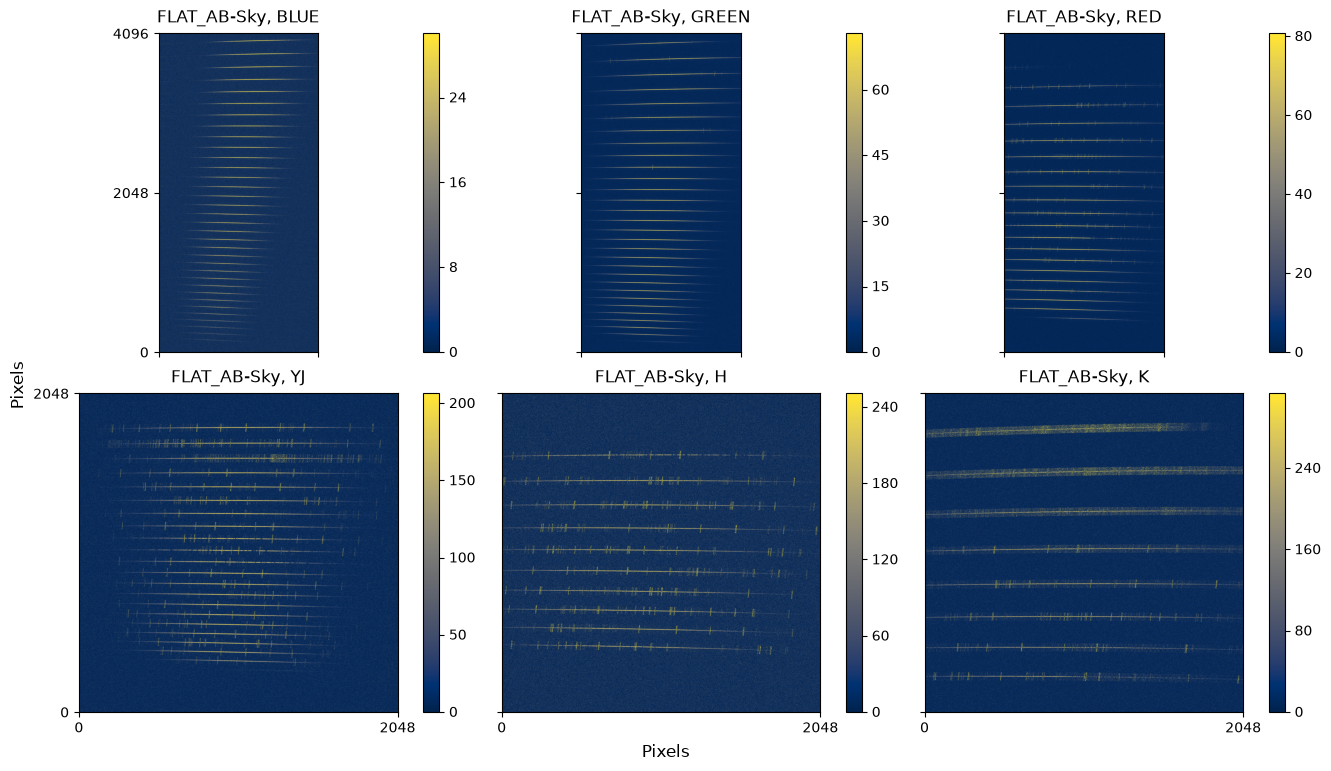

In [8]:
# Each on-source integration has an independent matching blank exposure.
# Combine unique detector frames before optimal extraction, so shared pixels are counted once.
science_dits = [dit for dit, count in SCIENCE_EXPOSURES[DETECTOR_MODE]]
science_ndits = [count for dit, count in SCIENCE_EXPOSURES[DETECTOR_MODE]]
science_sources = {"FLAT_AB": sim_tp.misc.point_source(sed=source_templates.ab_spectrum(mag=20))}
for objname, source in science_sources.items():
    hduls, science_train = update_params_and_observe(object_name=objname, imagetype="RAW_OBJECT", source=source,
                                        exptimes=science_dits, ndit=science_ndits, output_dir=output_dir, **args)
    sky_hduls, _ = update_params_and_observe(object_name=f"{objname}_sky", imagetype="SKY", source=None,
                                            exptimes=science_dits, ndit=science_ndits, output_dir=output_dir, **args)
    sub_hdul = combine_readouts([hduls[0], sky_hduls[0]], [1, -1], source_indices=[0])
    save_zshooter_readout(sub_hdul, output_dir, object_name=f"{objname}_SUB", imagetype="SCIENCE", extra_headers={"SUBTRACTED": True})
    del hduls, sky_hduls
_ = plot_readout_overview(sub_hdul, titles=[f"{objname}-Sky, {chan}" for chan in ["BLUE", "GREEN", "RED", "YJ", "H", "K"]])
del sub_hdul
exposure_table = pd.DataFrame(exposure_rows, columns=["object", "detector_mode", "arm", "DIT", "NDIT", "on_source_s", "peak_e_per_integration", "usable_well_e", "F", "read_noise_total_e", "dark_e_s"])
exposure_table["well_fraction"] = exposure_table["peak_e_per_integration"]/exposure_table["usable_well_e"]
exposure_table.to_csv(output_dir/"exposures.csv", index=False)
display(exposure_table)


In [9]:
REDUCED_DIR = output_dir / "reduced"
REDUCED_DIR.mkdir(exist_ok=True)

In [12]:
from zsdrp.ZSHOOTER import ZSHOOTER

zspy = ZSHOOTER()
files = {}
for chan in zspy.config.channels:
    stepnames = ['bias','flat','trace','wavecal_master','science']
    file_groups = zspy.sort_files(str(output_dir), target='', night='', channel=chan, steps=stepnames)
    # Calibration-only nights can precede the single science group returned by PyReduce.
    (_, fls), = [entry for entry in file_groups if len(entry[1]['science'])]
    files[chan] = {name: fls[name] for name in stepnames}
    if DETECTOR_MODE == 'SPEC' and chan != 'YJ':
        files[chan]['trace'] = files[chan]['flat']
# files[chan]

100%|██████████| 60/60 [00:00<00:00, 861.40it/s]

WARNING - Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Could not find any files for step 'science' with settings {'instrument': 'ZShooter_v2', 'night': datetime.date(2026, 10, 19), 'channel': n


100%|██████████| 60/60 [00:00<00:00, 1099.20it/s]

WARNING - Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Could not find any files for step 'science' with settings {'instrument': 'ZShooter_v2', 'night': datetime.date(2026, 10, 19), 'channel': n


100%|██████████| 60/60 [00:00<00:00, 872.78it/s]

...

100%|██████████| 60/60 [00:00<00:00, 1083.52it/s]

WARNING - Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20


WARNING - Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Could not find any files for step 'science' with settings {'instrument': 'ZShooter_v2', 'night': datetime.date(2026, 10, 19), 'channel': np.str_('H')}, sharing parameters ['instrument', 'night', 'channel']
pyreduce.instruments.common - WARNING: Could not find any files for step 'science' with settings {'instrument': 'ZShooter_v2', 'night': d

100%|██████████| 60/60 [00:00<00:00, 717.67it/s]

WARNING - Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'flat' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'trace' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'curvature' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
pyreduce.instruments.common - WARNING: Using 'wavecal_master' files from night 2026-10-19 for observations of night 2026-10-20
WARNING - Could not find any files for step 'science' with settings {'instrument': 'ZShooter_v2', 'night': datetime.date(2026, 10, 19), 'channel': n

In [13]:
from scopesim.source.source_templates import ab_spectrum
from synphot.units import convert_flux
from pyreduce.spectra import Spectra

reference = ab_spectrum(mag=16)
reference_wave = reference.waveset
reference_flux = convert_flux(reference_wave, reference(reference_wave), "FLAM")
# Establish the flat-AB control before extracting the fainter science scenes.
results = {}
for channel, group in files.items():
    controls = [path for path in group['science'] if fits.getheader(path)['OBJECT'] in ('STANDARD', 'FLAT_AB_SUB')]
    selected = {channel: {**group, 'science': controls}}
    reduced = zsdrp.pipe.run_reduction(selected, channels=[channel], output_dir=REDUCED_DIR, disable_steps=['mask'],
                                      print_params=False, disable_all_plots=True, reuse_cals=not rebuild_cals, require_variance=True, trace_list=science_train['trace_list_analytical'])
    # Flux calibration converts its inputs in place; preserve the standard in original electron units.
    reduced[channel]['spectra']['STANDARD'].save(REDUCED_DIR / f'standard_{channel}_extracted_electrons.fits')
    calibrated = zsdrp.pipe.run_flux_calibration_and_stitch(reduced, reference_wave=reference_wave, reference_flux=reference_flux,
                                                          plot=False, output_dir=str(REDUCED_DIR))
    cal = reduced[channel]
    del cal['spectra'], cal['norm']
    results[channel] = cal
    del reduced, calibrated

Running reduction for channel BLUE...
WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead


Trace: 100%|██████████| 34/34 [00:03<00:00,  8.69it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 587/597 lines, channel -0.003 -0.006 x/nx px, rms 0.088 px
WARNING - Traces not ordered by y-position at x=1242: trace 1 (y=3831.0) < trace 0 (y=4001.8) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_BLUE.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1242: trace 1 (y=3831.0) < trace 0 (y=4001.8) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_BLUE.fits
WARNING - Traces not ordered by y-position at x=1242: trace 2 (y=3665.4) < trace 1 (y=3831.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_A

Trace: 100%|██████████| 30/30 [00:06<00:00,  4.58it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 703/712 lines, channel -0.001 -0.005 x/nx px, rms 0.048 px
WARNING - Traces not ordered by y-position at x=1024: trace 1 (y=3765.4) < trace 0 (y=3973.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_GREEN.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 1 (y=3765.4) < trace 0 (y=3973.0) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_GREEN.fits
WARNING - Traces not ordered by y-position at x=1024: trace 2 (y=3566.7) < trace 1 (y=3765.4) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC

...

WARNING - Could not fit curvature for trace 18, using zero curvature
pyreduce.slit_curve - WARNING: Could not fit curvature for trace 18, using zero curvature
WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 126/128 lines, channel +0.010 -0.011 x/nx px, rms 0.046 px
WARNING - Traces not ordered by y-position at x=1024: trace 1 (y=1727.8) < trace 0 (y=1828.5) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_YJ.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 1 (y=1727.8) < trace 0 (y=1828.5) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_YJ.fits
WARNING - Traces not orde

Trace: 100%|██████████| 10/10 [00:00<00:00, 12.72it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 72/72 lines, channel -0.006 +0.000 x/nx px, rms 0.054 px
WARNING - Traces not ordered by y-position at x=1024: trace 1 (y=1487.2) < trace 0 (y=1652.3) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_H.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 1 (y=1487.2) < trace 0 (y=1652.3) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_H.fits
WARNING - Traces not ordered by y-position at x=1024: trace 2 (y=1330.4) < trace 1 (y=1487.2) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT

Trace: 100%|██████████| 8/8 [00:00<00:00, 11.82it/s]


WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
simple_wavesol: 53/53 lines, channel +0.038 -0.064 x/nx px, rms 0.053 px
WARNING - Traces not ordered by y-position at x=1004: trace 1 (y=1544.9) < trace 0 (y=1820.6) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_K.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1004: trace 1 (y=1544.9) < trace 0 (y=1820.6) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_K.fits
WARNING - Traces not ordered by y-position at x=1004: trace 2 (y=1288.5) < trace 1 (y=1544.9) when saving to /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT

## YJ arc exposure check

The initial 2 s YJ arc above failed to measure the slit tilt in order 76 and PyReduce substituted zero. The explicit 3 s trial remains below the configured well and measures the tilt again. The final YJ reduction and diagnostics below use that 3 s arc; the production kilonova notebook starts with 3 s. This notebook retains the initial trial to make that choice inspectable.

In [16]:
from zsdrp.steps import CurvatureWrapper, TraceWrapper
from zsdrp.utils import load_instrument_settings
from astropy.table import Table

diagnostic_dir = REDUCED_DIR/"diagnostics"
diagnostic_dir.mkdir(exist_ok=True)

# Increase arc signal for the H2RG curvature fit; DIT is an explicit observing choice.
ARC_YJ_TRIAL_DIT = 3.
trial_dits = CALIBRATION_DITS[DETECTOR_MODE]["arcs"].copy()
yj_index = zspy.config.channels.index("YJ")
trial_dits[yj_index] = ARC_YJ_TRIAL_DIT
trial_dir = output_dir/"yj_arc_3s"
trial_hduls, trial_train = update_params_and_observe(object_name="arcs_3s", imagetype="ARCS", source=LAMP,
    exptimes=trial_dits, output_dir=trial_dir, disable_effects=disable_effects_cals, **args)
print("YJ trial peak / usable well:", trial_hduls[0][yj_index][1].header["PEAKDIT"], trial_hduls[0][yj_index][1].header["WELLDEP"])
del trial_hduls, trial_train

trial_bias, trial_bhead = results["YJ"]["master_bias"]
trial_arc = zsdrp.pipe.combine_calibrate(files=[str(trial_dir/"arcs_3s_0_YJ.fits")], instrument=zspy, channel="YJ", bias=trial_bias, bhead=trial_bhead)
trial_settings = load_instrument_settings(zspy)["YJ"]["curvature"].copy()
trial_settings["plot"] = False
trial_traces = TraceWrapper.load(REDUCED_DIR/"trace_YJ.fits")
original_tilts = {trace.m: trace.slit[1, 0] for trace in trial_traces}
trial_traces = CurvatureWrapper.run(trial_arc[0], trial_traces, step_cfg=trial_settings, print_params=False)
curvature_trial = Table(rows=[(trace.m, original_tilts[trace.m], trace.slit[1, 0]) for trace in trial_traces],
    names=("order", "tilt_2s_pix_per_pix", "tilt_3s_pix_per_pix"))
curvature_trial.write(diagnostic_dir/"yj_arc_curvature_trial.ecsv", overwrite=True)
display(curvature_trial)
del trial_arc, trial_bias, trial_bhead, trial_traces


Simulating arcs_3s
Peak electrons per integration: [11429, 37300, 17763, 50221, 28685, 30299]
update_params_and_observe(arcs_3s): 59.1 s
YJ trial peak / usable well: 50221.37713886652 60000
WARNING - No exposure time set in bias, using number of files instead
pyreduce.combine_frames - WARNING: No exposure time set in bias, using number of files instead
WARNING - Traces not ordered by y-position at x=1024: trace 1 (y=1727.8) < trace 0 (y=1828.5) loaded from /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_YJ.fits
pyreduce.trace_model - WARNING: Traces not ordered by y-position at x=1024: trace 1 (y=1727.8) < trace 0 (y=1828.5) loaded from /Users/jibailey/src/zs-scopesim/notebooks/01_Kilonovae_detectors/SPEC_ALTDETECT_yj_h2rg/kilonova_X-1.3_NS-0.7_dark_slit-0.7_ao-0_optimal_variance/reduced/trace_YJ.fits
WARNING - Traces not ordered by y-position at x=1024: trace 2 (y=1630.6) < 

Trace: 100%|██████████| 22/22 [00:01<00:00, 15.54it/s]


order,tilt_2s_pix_per_pix,tilt_3s_pix_per_pix
int64,float64,float64
58,0.08464188210403363,0.0847647268420855
59,0.08482403179938112,0.0849348826036261
60,0.08477020959443984,0.08501215038134886
61,0.08466801587485516,0.084809816797001
62,0.08462296084953692,0.08465993588515694
63,0.08470105260386739,0.08462091381268474
64,0.08423659849912693,0.08475091509990511
65,0.08467591907234054,0.08479789265673156
66,0.08507602806222318,0.08466532140932227


In [ ]:
# Adopt the measured 3 s YJ arc and rebuild that channel's calibrations.
channel = "YJ"
files[channel]["wavecal_master"] = [str(trial_dir/"arcs_3s_0_YJ.fits")]
group = files[channel]
controls = [path for path in group["science"] if fits.getheader(path)["OBJECT"] in ("STANDARD", "FLAT_AB_SUB")]
selected = {channel: {**group, "science": controls}}
reduced = zsdrp.pipe.run_reduction(selected, channels=[channel], output_dir=REDUCED_DIR, disable_steps=["mask"],
    print_params=False, disable_all_plots=True, reuse_cals=False, require_variance=True, trace_list=science_train["trace_list_analytical"])
reduced[channel]["spectra"]["STANDARD"].save(REDUCED_DIR/f"standard_{channel}_extracted_electrons.fits")
calibrated = zsdrp.pipe.run_flux_calibration_and_stitch(reduced, reference_wave=reference_wave, reference_flux=reference_flux,
    plot=False, output_dir=str(REDUCED_DIR))
cal = reduced[channel]
del cal["spectra"], cal["norm"]
results[channel] = cal
del reduced, calibrated

exposure_table = pd.DataFrame(exposure_rows, columns=["object", "detector_mode", "arm", "DIT", "NDIT", "on_source_s", "peak_e_per_integration", "usable_well_e", "F", "read_noise_total_e", "dark_e_s"])
exposure_table["well_fraction"] = exposure_table["peak_e_per_integration"]/exposure_table["usable_well_e"]
exposure_table.to_csv(output_dir/"exposures.csv", index=False)


In [ ]:
from astropy.io import fits
from astropy.table import Table
from matplotlib.colors import LogNorm

diagnostic_dir = REDUCED_DIR / "diagnostics"
diagnostic_dir.mkdir(exist_ok=True)
calibration_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (channel, cal) in zip(axes.ravel(), results.items(), strict=True):
    traces = [t for t in cal['traces'] if not t.invalid]
    row_for_order = {t.m: i for i, t in enumerate(traces)}
    residuals = []
    for line in cal['arc_lines']:
        order = int(line['order'].rsplit('_', 1)[1])
        trace = traces[row_for_order[order]]
        if not trace.column_range[0] <= line['x'] < trace.column_range[1]:
            continue
        wavelength = cal['wave_img'][row_for_order[order]]
        x = np.arange(wavelength.size)
        residuals.append((np.interp(line['x'], x, wavelength) - line['line']) / np.interp(line['x'], x, np.abs(np.gradient(wavelength))))
    calibration_rows.append((channel, len(traces), len(residuals), np.median(np.abs(residuals)), np.percentile(np.abs(residuals), 95)))
    image = fits.getdata(files[channel]['trace'][0], 1) - cal['master_bias'][0]
    ax.imshow(np.maximum(image, 1), origin='lower', cmap='gray', norm=LogNorm(1, 60000))
    for t in traces:
        x = np.arange(*t.column_range)
        ax.plot(x, t.y_at_x(x), color='tomato', linewidth=0.5)
        xc = x[len(x)//2]
        ax.text(xc, t.y_at_x(xc), str(t.m), color='cyan', fontsize=5)
    ax.set_title(f"{channel}: {len(traces)} measured orders")
    ax.set_xlabel("Detector x (pixel)")
    ax.set_ylabel("Detector y (pixel)")
    ax.set_xlim(0, image.shape[1]-1)
    ax.set_ylim(0, image.shape[0]-1)
calibration_summary = Table(rows=calibration_rows, names=['channel', 'orders', 'arc_lines', 'median_abs_residual_pix', 'p95_abs_residual_pix'])
calibration_summary['median_abs_residual_pix'].info.format = '.3f'
calibration_summary['p95_abs_residual_pix'].info.format = '.3f'
display(calibration_summary)
calibration_summary.write(diagnostic_dir / "calibration.csv", format='ascii.csv', overwrite=True)
fig.tight_layout()
fig.savefig(diagnostic_dir / "measured_traces.png", dpi=180)
plt.show()

In [ ]:
from zs_scopesim_tools.reduction_checks import flat_ab_extraction_bins, flat_ab_band_integrals
from zsdrp.steps import TraceWrapper

# Fixed comparison windows exclude broad inter-band gaps but retain narrow transmission features.
# Selection never uses the noisy recovered flux.
flat_windows = {'BLUE': (3500, 4000), 'GREEN': (4800, 6000), 'RED': (8000, 8800), 'YJ': (12000, 13000), 'H': (15500, 17000), 'K': (21000, 22000)}
flat_files = {channel: REDUCED_DIR / f'spectra_FLAT_AB_SUB_{channel}_fluxcal.fits' for channel in flat_windows}
flat_intervals = {channel: [u.Quantity(limits, u.AA)] for channel, limits in flat_windows.items()}
native_gap = {}
for channel in flat_windows:
    traces = [trace for trace in TraceWrapper.load(REDUCED_DIR / f'trace_{channel}.fits') if not trace.invalid]
    with np.load(REDUCED_DIR / f'wavecal_{channel}.npz') as calibration:
        native_steps = np.concatenate([np.diff(wave[trace.column_range[0]:trace.column_range[1]]) for wave, trace in zip(calibration['wave_img'], traces, strict=True)])
    native_gap[channel] = np.max(np.abs(native_steps)) * u.AA
flat_bins, flat_figure = flat_ab_extraction_bins(flat_files, intervals=flat_intervals, max_gap=native_gap, magnitude=20, bin_R=1000)
flat_bins.write(diagnostic_dir / 'flat_ab_bins.ecsv', overwrite=True)
flat_figure.savefig(diagnostic_dir / 'flat_ab_recovery.png', dpi=160)
flat_bands = flat_ab_band_integrals(flat_files, intervals=flat_intervals, max_gap=native_gap, magnitude=20)
flat_bands.write(diagnostic_dir / 'flat_ab_bands.ecsv', overwrite=True)
display(flat_bands['arm', 'covered_width', 'ratio', 'ratio_uncertainty', 'snr'])
plt.show()

In [ ]:
# Check the order whose curvature fit failed with the initial arc exposure.
with np.load(Path(zspy._inst_dir)/"free_spectral_ranges.npz") as fsrs:
    order76_interval = fsrs["YJ"][np.flatnonzero(fsrs["YJ_orders"] == 76)[0]]*u.AA
yj_files = {"YJ": flat_files["YJ"]}
yj_intervals = {"YJ": [order76_interval]}
yj_gap = {"YJ": native_gap["YJ"]}
yj_order76 = flat_ab_band_integrals(yj_files, intervals=yj_intervals, max_gap=yj_gap, magnitude=20)
yj_order76.write(diagnostic_dir/"yj_order76_flux.ecsv", overwrite=True)
display(yj_order76["arm", "covered_width", "ratio", "ratio_uncertainty", "snr"])
yj_bins, yj_figure = flat_ab_extraction_bins(yj_files, intervals=yj_intervals, max_gap=yj_gap, magnitude=20, bin_R=1000)
yj_figure.savefig(diagnostic_dir/"yj_order76_recovery.png", dpi=160)
plt.show()
